In [1]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from scipy.integrate import solve_ivp
from scipy.optimize import minimize
import numpy as np
import math
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from matplotlib.lines import Line2D

In [2]:
df = pd.read_csv('INPUT/scRNAseq/theta_Zspace_annotation.csv').set_index('CellID')
import numpy as np
import matplotlib.pyplot as plt

# choose rotation angle (degrees)
angle_deg = 30
theta = np.deg2rad(angle_deg)

# original coordinates
x = df['Z_space1'].values
y = df['Z_space2'].values

# rotation
x_rot = x * np.cos(theta) - y * np.sin(theta)
y_rot = x * np.sin(theta) + y * np.cos(theta)

df['Z_space1'] = x_rot
df['Z_space2'] = y_rot


In [ ]:

df = df[df['Cell type'] != 'Wnt. inh. state'].copy() 

# ------------ 2) ctrl working set, drop time = 0
df_ctrl = df[df['Condition'] == 'ctrl'].copy()
before = df_ctrl.shape[0]
df_ctrl = df_ctrl[df_ctrl['Time_int'] > 0].copy()
print(f"[CTRL] kept {df_ctrl.shape[0]} rows (dropped {before - df_ctrl.shape[0]} with time> 48)")

# ------------ 3) Duplicate ALL ctrl cells with time < 72h ------------
df_ctrl_pre72 = df_ctrl[df_ctrl['Time_int'].astype(float) < 72].copy()
df_ctrl_pre72['Condition'] = 'cdk'
df_cdk = df[df['Condition'] == 'cdk']

df_cdk = pd.concat([df_cdk, df_ctrl_pre72], ignore_index=True)

# ------------ 4) Final names ------------
control_df = df_ctrl.reset_index(drop=True)
cdk_df     = df_cdk.reset_index(drop=True)


[CTRL] kept 14817 rows (dropped 367 with time> 48)


In [4]:
def load_tree_core(path="INPUT/scRNAseq/Continuous_traj_periods_TREE_core.npz"):
    data = np.load(path, allow_pickle=False) 
    return data["node_xy"], data["node_values"], data["edges"]

node_xy, CC_periods, connections = load_tree_core()


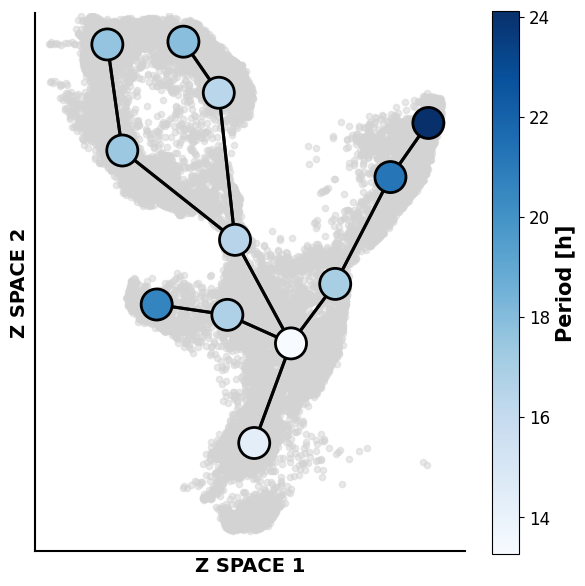

In [5]:


# --- load tree ---
def load_tree_core(path="INPUT/scRNAseq/Continuous_traj_periods_TREE_core.npz"):
    data = np.load(path, allow_pickle=False) 
    return data["node_xy"], data["node_values"], data["edges"]

node_xy, node_values, edges = load_tree_core()

# --- Plot ---
fig, ax = plt.subplots(figsize=(6, 6))

# Background cells
ax.scatter(
    df_ctrl['Z_space1'], 
    df_ctrl['Z_space2'], 
    s=20, 
    c='lightgrey', 
    alpha=0.5, 
    zorder=0
)

# Draw edges first (behind nodes)
edge_color = 'black'
edge_lw = 2.2
edge_alpha = 0.9
for u, v in edges:
    ax.plot(
        [node_xy[u, 0], node_xy[v, 0]],
        [node_xy[u, 1], node_xy[v, 1]],
        color=edge_color,
        linewidth=edge_lw,
        alpha=edge_alpha,
        zorder=1
    )
    ax.annotate(
        '',
        xy=(node_xy[v, 0], node_xy[v, 1]),
        xytext=(node_xy[u, 0], node_xy[u, 1]),
        arrowprops=dict(
            arrowstyle='->',
            color=edge_color,
            lw=edge_lw,
            alpha=edge_alpha
        ),
        zorder=1
    )

# Plot cluster nodes on top
sc = ax.scatter(
    node_xy[:, 0], node_xy[:, 1],
    c=node_values,
    cmap='Blues',
    s=500,
    edgecolor='black',
    linewidth=2,
    zorder=2
)

# Colorbar
cbar = plt.colorbar(sc, ax=ax)
cbar.set_label('Period [h]', fontsize=15, weight='bold')
cbar.ax.tick_params(labelsize=12)

# Axis limits
xlim = (-5, 11)
ylim = (-17, 3)
ax.set_xlim(xlim)
ax.set_ylim(ylim)

# Axes styling
ax.set_xlabel("Z SPACE 1", fontsize=14, weight='bold')
ax.set_ylabel("Z SPACE 2", fontsize=14, weight='bold')
ax.set_xticks([])
ax.set_yticks([])
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_linewidth(1.5)
ax.set_aspect('equal', adjustable='box')

plt.tight_layout()

fig.savefig(
    "FIGURES/Cellcycle_period_continuous.png",
    dpi=500,
    bbox_inches="tight",
    transparent=True
)


plt.show()

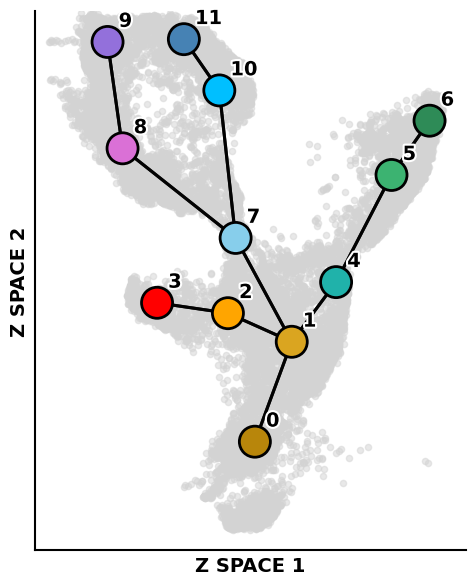

In [6]:
# --- Define palette ---
palette = [
    'darkgoldenrod', 'goldenrod', 'orange', 'red','lightseagreen','mediumseagreen', 'seagreen',
     'skyblue', 'orchid', 'mediumpurple',
    'deepskyblue', 'steelblue'
]

# Node IDs are now sequential from 0 to 11 (cluster_id)
n_nodes = node_xy.shape[0]
colors_for_nodes = [palette[i % len(palette)] for i in range(n_nodes)]

# --- Plot ---
fig, ax = plt.subplots(figsize=(6, 6))

# Background cells
ax.scatter(
    df_ctrl['Z_space1'], 
    df_ctrl['Z_space2'], 
    s=20, 
    c='lightgrey', 
    alpha=0.5, 
    zorder=0
)

# Draw edges first (behind nodes)
edge_color = 'black'
edge_lw = 2.2
edge_alpha = 0.9
for u, v in edges:
    ax.plot(
        [node_xy[u, 0], node_xy[v, 0]],
        [node_xy[u, 1], node_xy[v, 1]],
        color=edge_color,
        linewidth=edge_lw,
        alpha=edge_alpha,
        zorder=1
    )
    ax.annotate(
        '',
        xy=(node_xy[v, 0], node_xy[v, 1]),
        xytext=(node_xy[u, 0], node_xy[u, 1]),
        arrowprops=dict(
            arrowstyle='->',
            color=edge_color,
            lw=edge_lw,
            alpha=edge_alpha
        ),
        zorder=1
    )

# Plot cluster nodes on top with custom colors
sc = ax.scatter(
    node_xy[:, 0], node_xy[:, 1],
    c=colors_for_nodes,
    s=500,
    edgecolor='black',
    linewidth=2,
    zorder=2
)

# Annotate nodes with cluster numbers
for i, (x, y) in enumerate(node_xy):
    ax.annotate(
        str(i), (x, y),
        textcoords="offset points", xytext=(8, 8),
        ha="left", va="bottom", fontsize=14, fontweight='bold', color="black",
        path_effects=[pe.withStroke(linewidth=3, foreground="white")],
        zorder=3
    )

# Axis limits
xlim = (-5, 11)
ylim = (-17, 3)
ax.set_xlim(xlim)
ax.set_ylim(ylim)

# Axis labels
ax.set_xlabel("Z SPACE 1", fontsize=14, weight='bold')
ax.set_ylabel("Z SPACE 2", fontsize=14, weight='bold')

# Remove ticks
ax.set_xticks([])
ax.set_yticks([])

# Spine styling
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_linewidth(1.5)

ax.set_aspect('equal', adjustable='box')
plt.tight_layout()

fig.savefig(
    "FIGURES/Population_model_nodes.png",
    dpi=500,
    bbox_inches="tight",
    transparent=True
)

plt.show()

/tmp/ipykernel_1796526/3189230044.py:52: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap("Reds")
/tmp/ipykernel_1796526/3189230044.py:56: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(control_df[X_COL], control_df[Y_COL], s=5, c=(0.85, 0.85, 0.85),


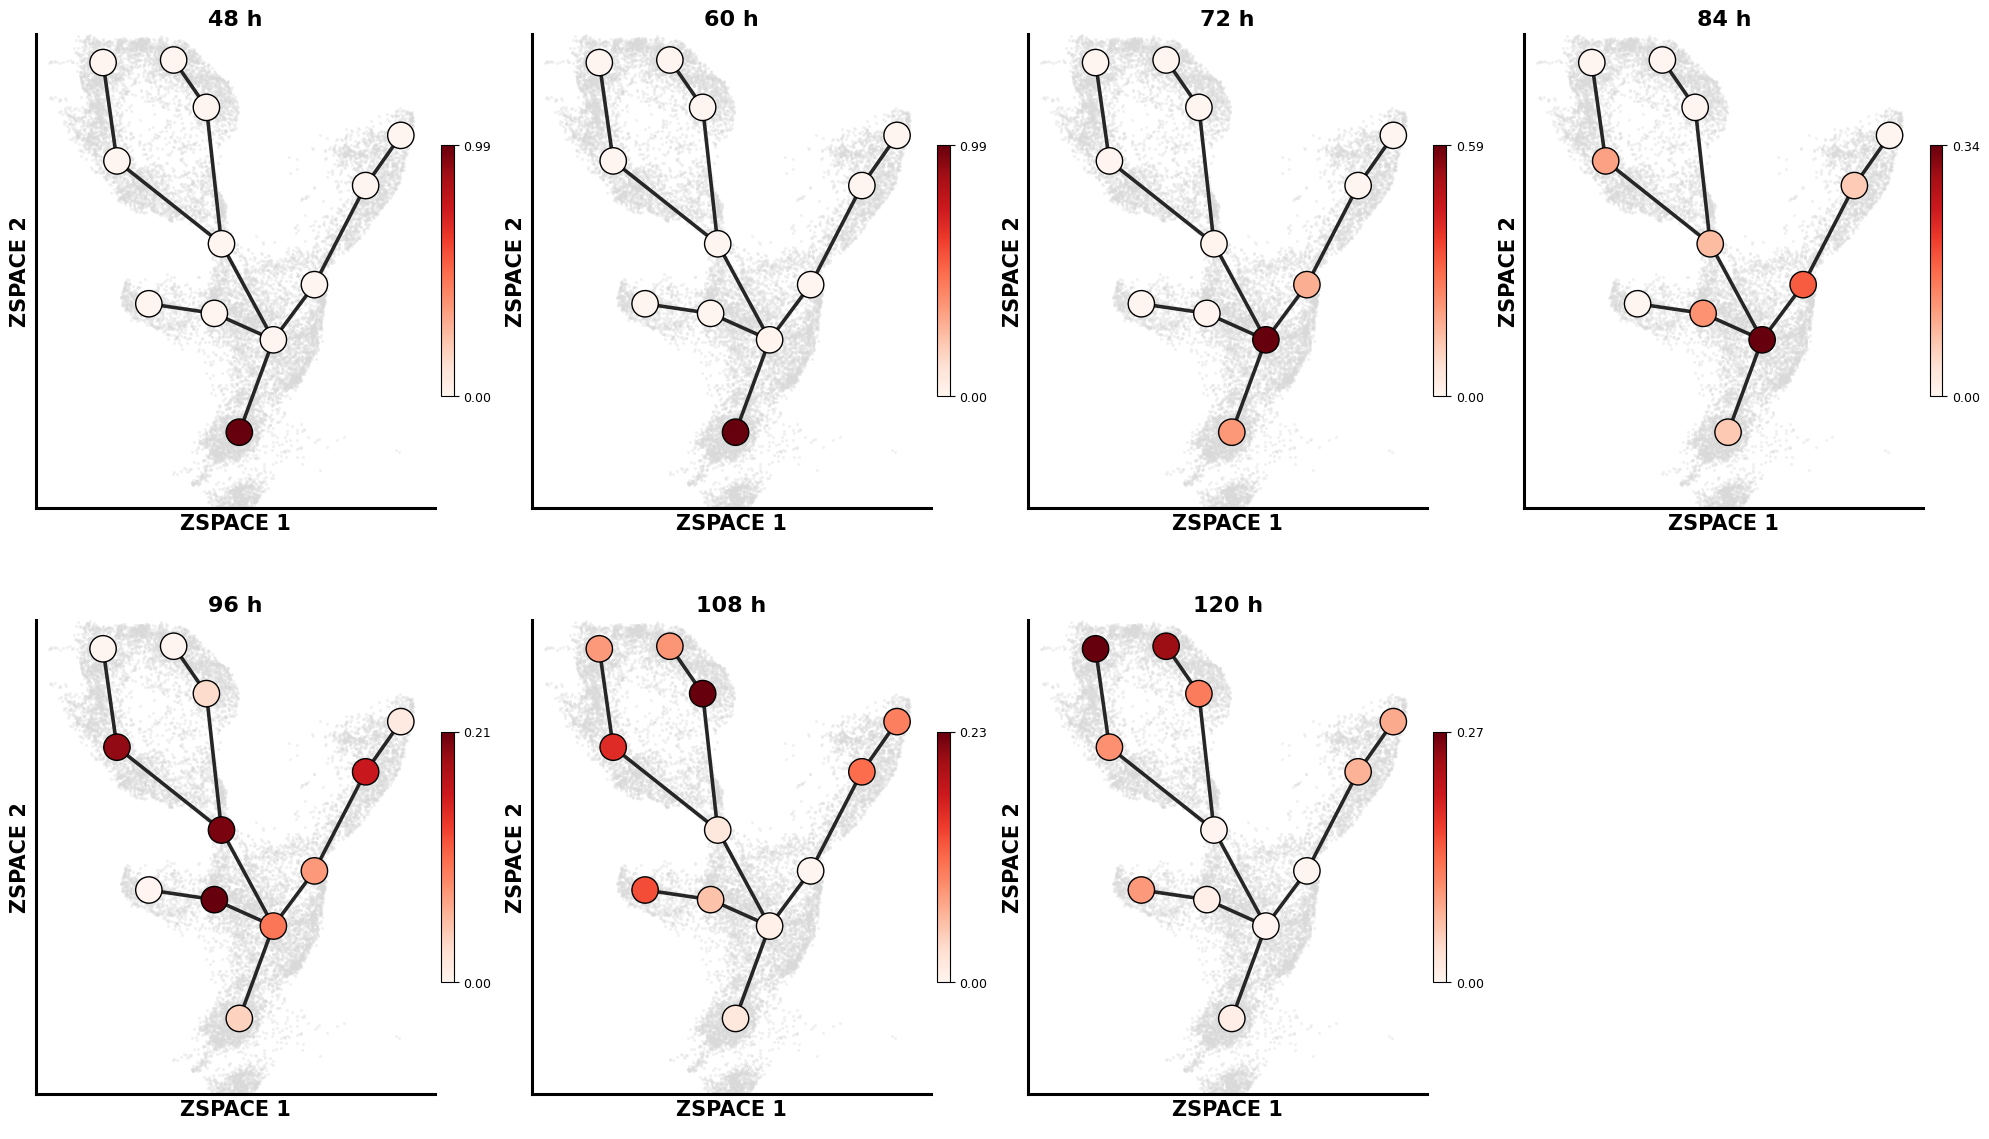

In [ ]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

# --- Parameters ---
X_COL = "Z_space1"
Y_COL = "Z_space2"
TIME_COL = "Time_int"

xlim = (-5, 11)
ylim = (-16, 3)

# --- Select valid nodes ---
finite = np.isfinite(CC_periods)
valid_idx = np.nonzero(finite)[0]
node_xy_valid = node_xy[valid_idx]
n_valid = len(valid_idx)

# --- Reindex edges ---
orig_to_valid = {orig: new for new, orig in enumerate(valid_idx)}
connections_valid = [(orig_to_valid[u], orig_to_valid[v]) 
                     for u, v in connections if u in orig_to_valid and v in orig_to_valid]

# --- Compute node proportions ---
cell_xy = control_df[[X_COL, Y_COL]].to_numpy()
D2 = ((cell_xy[:, None, :] - node_xy_valid[None, :, :])**2).sum(axis=2)
closest_valid_pos = D2.argmin(axis=1)

times = np.sort(control_df[TIME_COL].unique())
nT = len(times)
props = np.zeros((nT, n_valid), dtype=float)

for i, t in enumerate(times):
    m = control_df[TIME_COL].values == t
    if m.sum() > 0:
        cnt = np.bincount(closest_valid_pos[m], minlength=n_valid)
        props[i, :] = cnt / m.sum()

# --- Plotting: 2 rows x 3 columns ---
nrows, ncols = 2, 4

x_range = xlim[1] - xlim[0]
y_range = ylim[1] - ylim[0]
subplot_ratio = y_range / x_range  
fig_width = 5 * ncols
fig_height = fig_width * subplot_ratio * nrows / ncols  

fig, axes = plt.subplots(nrows, ncols, figsize=(fig_width, fig_height), sharex=True, sharey=True)
axes = np.atleast_1d(axes).ravel()

cmap = mpl.cm.get_cmap("Reds")

def draw_panel(ax, t_idx):
    # Background cells
    ax.scatter(control_df[X_COL], control_df[Y_COL], s=5, c=(0.85, 0.85, 0.85),
               alpha=0.35, linewidths=0, zorder=0)
    
    # Edges
    dark = (0.15, 0.15, 0.15)
    for u, v in connections_valid:
        ax.plot([node_xy_valid[u, 0], node_xy_valid[v, 0]],
                [node_xy_valid[u, 1], node_xy_valid[v, 1]],
                lw=2.6, c=dark, zorder=2)
    
    # Per-time normalization
    vmin, vmax = np.nanmin(props[t_idx]), np.nanmax(props[t_idx])
    if np.isclose(vmin, vmax):
        eps = 1e-6 if (vmin == 0) else 0.01 * abs(vmin)
        vmin -= eps
        vmax += eps
    norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax)
    
    # Nodes
    ax.scatter(node_xy_valid[:, 0], node_xy_valid[:, 1],
               c=props[t_idx, :], cmap=cmap, norm=norm,
               s=360, edgecolor="k", linewidth=1.0, zorder=3)
    
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_aspect('equal')
    
    # Styling
    ax.set_xlabel("ZSPACE 1", fontsize=15, fontweight='bold')
    ax.set_ylabel("ZSPACE 2", fontsize=15, fontweight='bold')
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    for spine in ["left", "bottom"]:
        ax.spines[spine].set_linewidth(2.2)
        ax.spines[spine].set_color("black")
    ax.set_xticks([]); ax.set_yticks([])
    
    # Bold time label
    ax.set_title(f"{times[t_idx]} h", fontweight="bold", fontsize=16)
    
    # Colorbar 
    sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, location="right", fraction=0.03, pad=0.015,
                        ticks=[vmin, vmax])
    cbar.ax.tick_params(labelsize=9)
    cbar.set_ticklabels([f"{vmin:.2f}", f"{vmax:.2f}"])

# Fill panels with timepoints
for i in range(min(nT, nrows*ncols)):
    ax = axes[i]
    draw_panel(ax, i)

# Turn off any extra axes
for k in range(nT, len(axes)):
    axes[k].axis('off')

# Tight spacing
plt.subplots_adjust(wspace=0.05, hspace=0.05)
fig.tight_layout()

fig.savefig(
    "FIGURES/Proportions_through_nodes.png",
    dpi=500,
    bbox_inches="tight",
    transparent=True
)

plt.show()


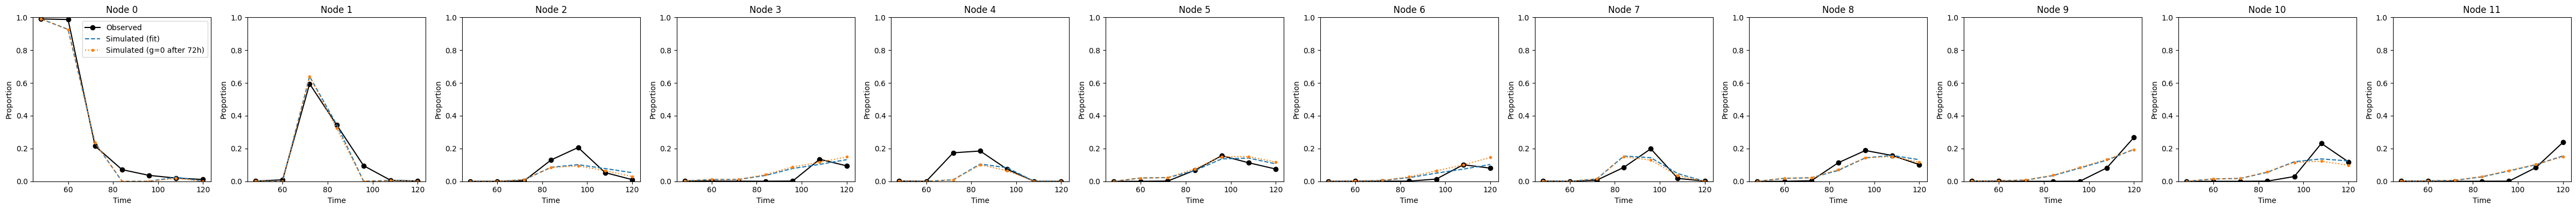

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import minimize

# --------------------------------------------
# Valid nodes and growth rates
# --------------------------------------------
finite = np.isfinite(CC_periods)
CC_valid = CC_periods[finite]
g = np.log(2) / CC_valid
n_nodes = len(CC_valid)

# --------------------------------------------
# Build W_mask
# --------------------------------------------
W_mask = np.zeros((n_nodes, n_nodes), dtype=bool)
for (u, v) in connections_valid:
    W_mask[u, v] = True

edge_positions = np.argwhere(W_mask)
n_edges = len(edge_positions)

# --------------------------------------------
# Prepare data
# --------------------------------------------
times = np.array(times)
P_obs = props / props.sum(axis=1, keepdims=True)
p0 = P_obs[0]
n_intervals = len(times) - 1

# --------------------------------------------
# Simulation used for fitting
# --------------------------------------------
def simulate_adaptive_W(W0_flat, deltas_flat, times, p0, g):
    deltas = deltas_flat.reshape(n_intervals, n_edges)

    W_prev = np.zeros((n_nodes, n_nodes))
    for w, (u, v) in zip(W0_flat, edge_positions):
        W_prev[u, v] = w

    p = p0.copy()
    P = [p.copy()]

    for k in range(n_intervals):
        W_curr = W_prev.copy()
        for d, (u, v) in zip(deltas[k], edge_positions):
            W_curr[u, v] *= (1 + d)

        def rhs(t, p):
            gbar = np.dot(g, p)
            dp = W_curr.T @ p - W_curr @ p
            dp += p * (g - gbar)
            return dp

        sol = solve_ivp(rhs, (times[k], times[k+1]), p, t_eval=[times[k+1]])
        p = sol.y[:, -1]
        p = np.clip(p, 0, None)
        p /= p.sum()

        P.append(p.copy())
        W_prev = W_curr

    return np.vstack(P)

# --------------------------------------------
# Loss
# --------------------------------------------
def loss_fn(params):
    W0 = params[:n_edges]
    deltas = params[n_edges:]
    P_sim = simulate_adaptive_W(W0, deltas, times, p0, g)
    return np.mean((P_sim - P_obs) ** 2)

# --------------------------------------------
# Fit
# --------------------------------------------
x0 = np.concatenate([
    0.01 * np.ones(n_edges),
    np.zeros(n_intervals * n_edges)
])

bounds = (
    [(0, None)] * n_edges +
    [(-0.3, 0.3)] * (n_intervals * n_edges)
)

res = minimize(loss_fn, x0, method="L-BFGS-B", bounds=bounds)

W0_fit = res.x[:n_edges]
deltas_fit = res.x[n_edges:]

P_sim = simulate_adaptive_W(W0_fit, deltas_fit, times, p0, g)

# --------------------------------------------
# Re-simulate with growth turned off after 72h
# --------------------------------------------
t_switch = 72.0

def simulate_with_growth_switch(W0_flat, deltas_flat, times, p0, g, t_switch):
    deltas = deltas_flat.reshape(n_intervals, n_edges)

    W_prev = np.zeros((n_nodes, n_nodes))
    for w, (u, v) in zip(W0_flat, edge_positions):
        W_prev[u, v] = w

    if (t_switch > times.min()) and (t_switch < times.max()) and not np.any(np.isclose(times, t_switch)):
        times_ext = np.sort(np.concatenate([times, [t_switch]]))
    else:
        times_ext = times.copy()

    p = p0.copy()
    P = [p.copy()]

    def orig_k(t_end):
        return max(0, np.searchsorted(times, t_end) - 1)

    for k in range(len(times_ext) - 1):
        t0, t1 = times_ext[k], times_ext[k+1]
        k_orig = orig_k(t1)

        W_curr = W_prev.copy()
        for d, (u, v) in zip(deltas[k_orig], edge_positions):
            W_curr[u, v] *= (1 + d)

        g_used = g if t0 < t_switch else np.zeros_like(g)

        def rhs(t, p):
            gbar = np.dot(g_used, p)
            dp = W_curr.T @ p - W_curr @ p
            dp += p * (g_used - gbar)
            return dp

        sol = solve_ivp(rhs, (t0, t1), p, t_eval=[t1])
        p = sol.y[:, -1]
        p = np.clip(p, 0, None)
        p /= p.sum()

        P.append(p.copy())
        W_prev = W_curr

    P = np.vstack(P)
    return P[np.isin(times_ext, times)]

P_sim_cdk = simulate_with_growth_switch(
    W0_fit, deltas_fit, times, p0, g, t_switch
)

# --------------------------------------------
# Plot
# --------------------------------------------
fig, axes = plt.subplots(1, n_nodes, figsize=(4 * n_nodes, 4))
axes = np.atleast_1d(axes)

for i, ax in enumerate(axes):
    ax.plot(times, P_obs[:, i], 'o-', color='k', label='Observed')
    ax.plot(times, P_sim[:, i], '--', label='Simulated (fit)')
    ax.plot(times, P_sim_cdk[:, i], ':.', label='Simulated (g=0 after 72h)')
    ax.set_title(f"Node {i}")
    ax.set_xlabel("Time")
    ax.set_ylabel("Proportion")
    ax.set_ylim(0, 1)
    if i == 0:
        ax.legend()

fig.tight_layout()
plt.show()


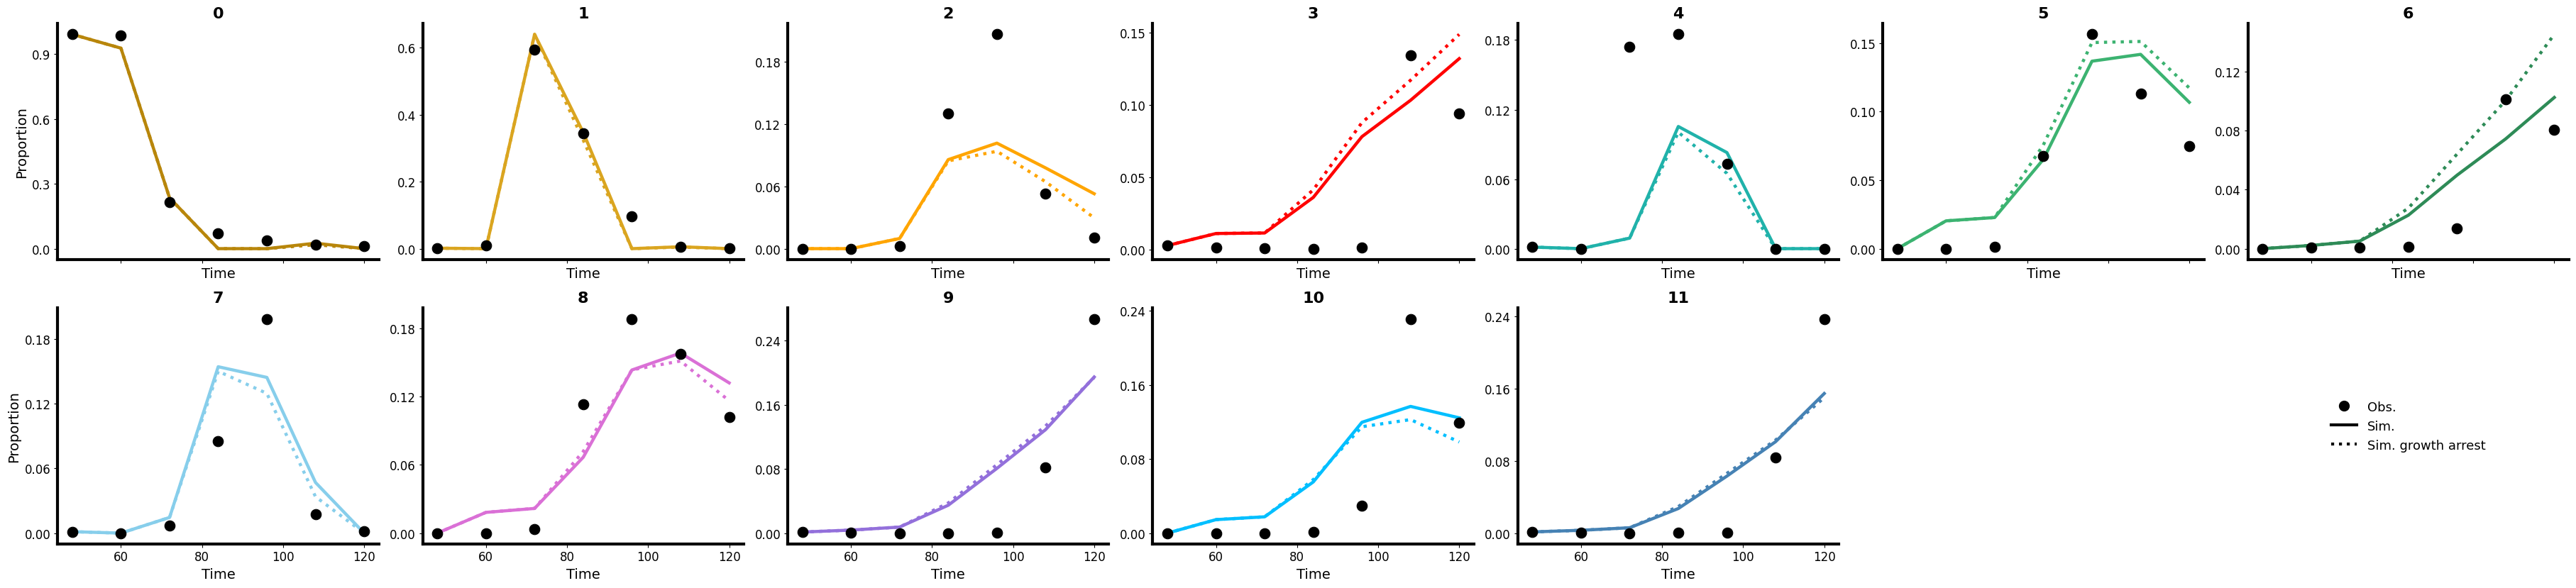

In [ ]:

palette = [
    'darkgoldenrod', 'goldenrod', 'orange', 'red','lightseagreen','mediumseagreen', 'seagreen',
     'skyblue', 'orchid', 'mediumpurple',
    'deepskyblue', 'steelblue'
]

times = np.asarray(times, dtype=float)
n_nodes = P_obs.shape[1]

# Reserve one extra panel for the legend
nrows = 2
ncols = int(math.ceil((n_nodes + 1) / 2))  

fig, axes = plt.subplots(nrows, ncols, figsize=(5.2*ncols, 4.2*nrows), sharex=True, sharey=False)
axes = np.atleast_1d(axes).ravel()

# Plot each node
for i in range(n_nodes):
    ax = axes[i]
    color_i = palette[i % len(palette)]

    ax.scatter(times, P_obs[:, i], s=110, color='k', edgecolor='k', linewidth=0.8, zorder=3)

    ax.plot(times, P_sim[:, i], color=color_i, lw=3.2, zorder=2)

    ax.plot(times, P_sim_cdk[:, i], color=color_i, lw=3.2, ls=':', zorder=2)

    ax.set_title(f"{i}", fontweight='bold', fontsize=16)

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    for spine in ["left", "bottom"]:
        ax.spines[spine].set_visible(True)
        ax.spines[spine].set_linewidth(3.0)
        ax.spines[spine].set_color("black")

    # fewer ticks on both axes
    ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=4))

    # labels & limits
    ax.set_xlabel("Time", fontsize=14)
    row, col = divmod(i, ncols)
    if col == 0:
        ax.set_ylabel("Proportion", fontsize=14)

    ax.tick_params(axis='both', which='major', labelsize=12)

legend_ax = axes[-1]
for k in range(n_nodes, len(axes) - 1):
    axes[k].axis('off')


legend_ax.axis('off')
dot_handle    = Line2D([0], [0], marker='o', linestyle='None',
                       markerfacecolor='k', markeredgecolor='k', color='k',
                       markersize=10, label='Obs.')
solid_handle  = Line2D([0], [0], color='k', lw=3.0, label='Sim.')
dotted_handle = Line2D([0], [0], color='k', lw=3.0, ls=':', label='Sim. growth arrest')
legend_ax.legend(handles=[dot_handle, solid_handle, dotted_handle],
                 loc='center', frameon=False, fontsize=13)

fig.tight_layout()

fig.savefig(
    "FIGURES/Proportions_fits_withga.png",
    dpi=500,
    bbox_inches="tight",
    transparent=True
)

plt.show()


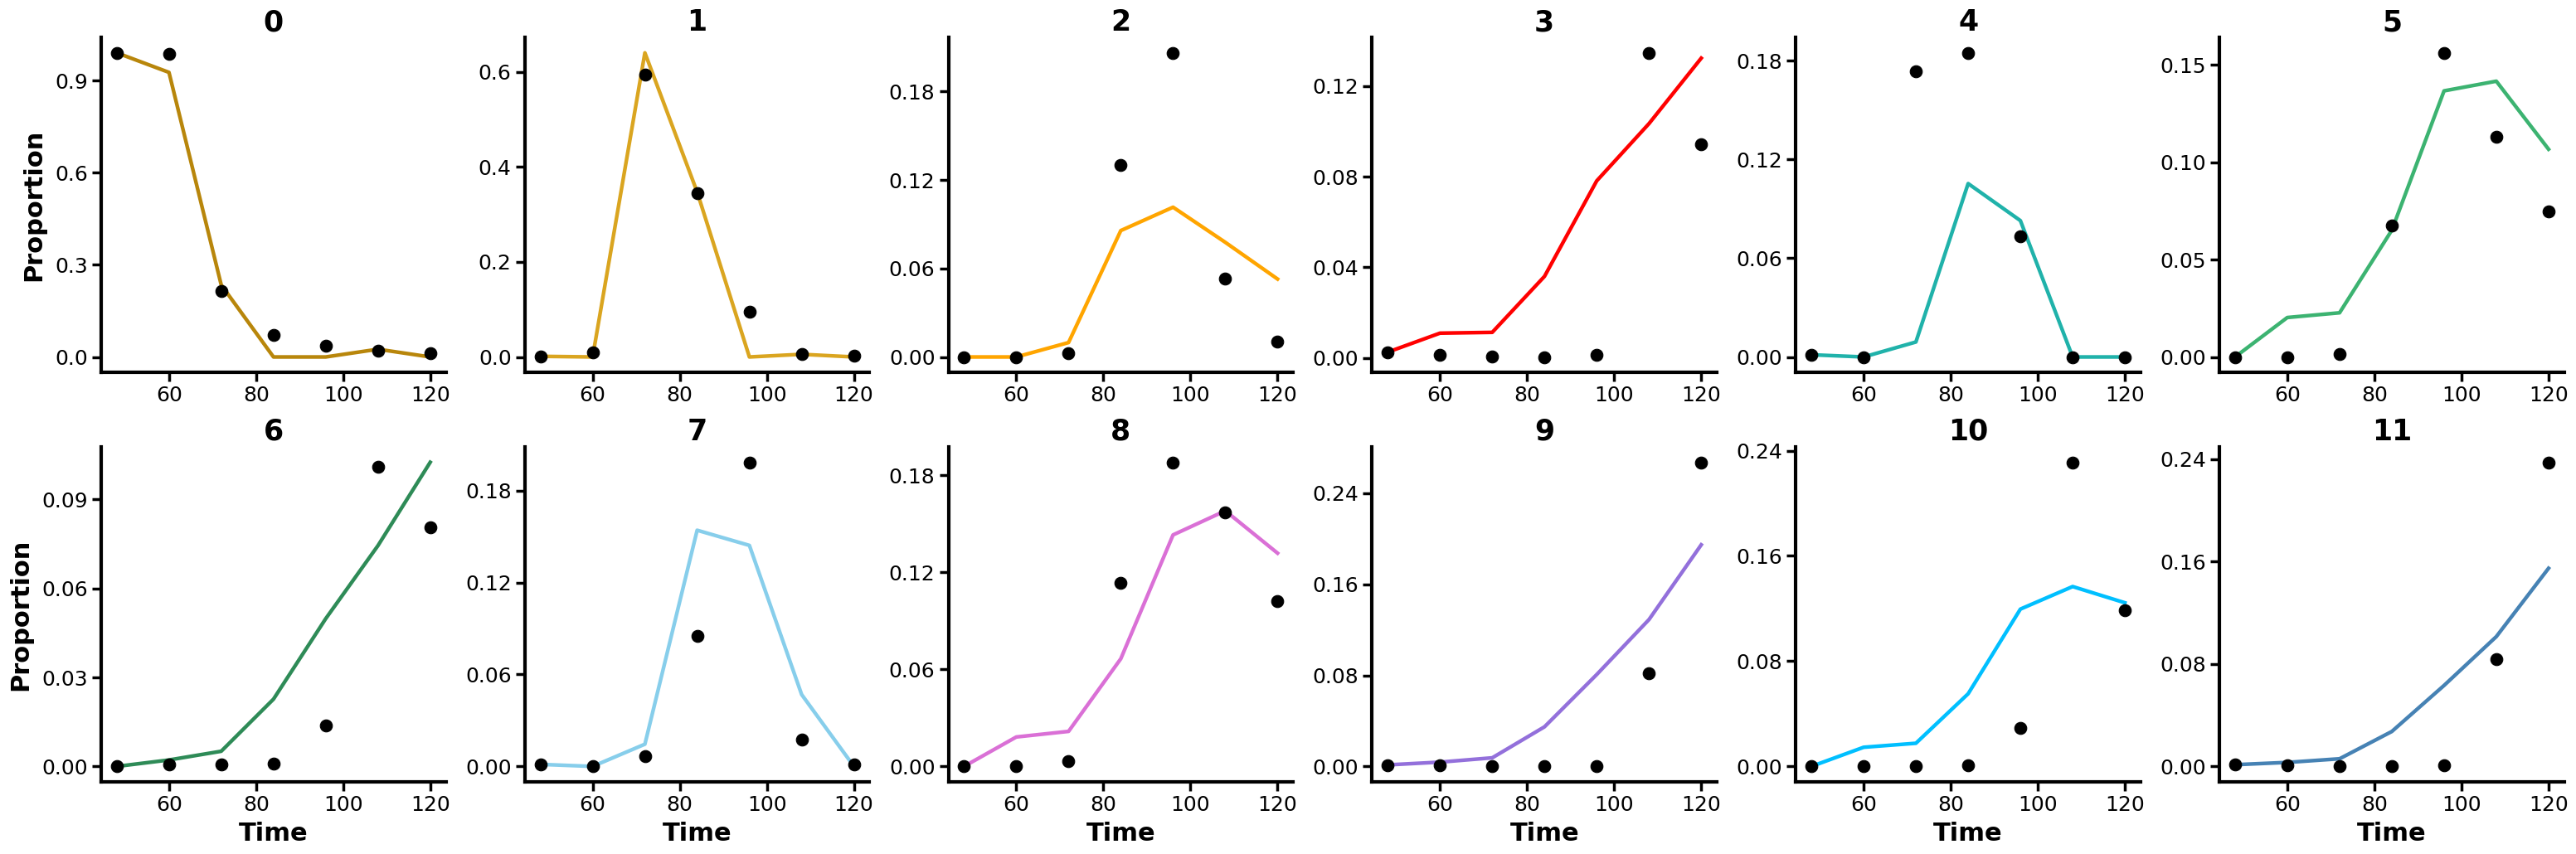

In [ ]:
times = np.asarray(times, dtype=float)
n_nodes = P_obs.shape[1]

# --- layout ---
nrows = 2
ncols = int(math.ceil(n_nodes / nrows))  
fig, axes = plt.subplots(nrows, ncols, figsize=(5.2*ncols, 5.2*nrows), sharey=False)
axes = np.atleast_1d(axes).ravel()

# --- plot each node ---
for i in range(n_nodes):
    ax = axes[i]
    color_i = palette[i % len(palette)]

    # observed points
    ax.scatter(times, P_obs[:, i], s=110, color='k', edgecolor='k', linewidth=0.8, zorder=3)

    # simulated control
    ax.plot(times, P_sim[:, i], color=color_i, lw=3.2, zorder=2)


    ax.set_title(f"{i}", fontweight='bold', fontsize=25)

    # spines
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    for spine in ["left", "bottom"]:
        ax.spines[spine].set_linewidth(3.0)
        ax.spines[spine].set_color("black")

    ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=4))

    row, col = divmod(i, ncols)
    if row == nrows - 1:
        ax.set_xlabel("Time", fontsize=22, fontweight='bold', labelpad=6)
    if col == 0:
        ax.set_ylabel("Proportion", fontsize=22, fontweight='bold', labelpad=8)

    ax.tick_params(axis='both', which='major', labelsize=18, width=2.5, length=8, direction='out')

for k in range(n_nodes, len(axes)):
    axes[k].axis('off')

if len(axes) > n_nodes:
    legend_ax = axes[-1]
    legend_ax.axis('off')
    dot_handle    = Line2D([0], [0], marker='o', linestyle='None',
                           markerfacecolor='k', markeredgecolor='k', color='k',
                           markersize=10, label='Obs.')
    solid_handle  = Line2D([0], [0], color='k', lw=3.0, label='Sim.')
    legend_ax.legend(handles=[dot_handle, solid_handle],
                     loc='center', frameon=False, fontsize=20)

fig.tight_layout()

fig.savefig(
    "FIGURES/Proportions_fits.png",
    dpi=500,
    bbox_inches="tight",
    transparent=True
)


plt.show()

/tmp/ipykernel_1796526/3626580554.py:65: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap_ab = mpl.cm.get_cmap("Blues")
/tmp/ipykernel_1796526/3626580554.py:31: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(control_df[X_COL], control_df[Y_COL],
/tmp/ipykernel_1796526/3626580554.py:96: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap_d = mpl.cm.get_cma

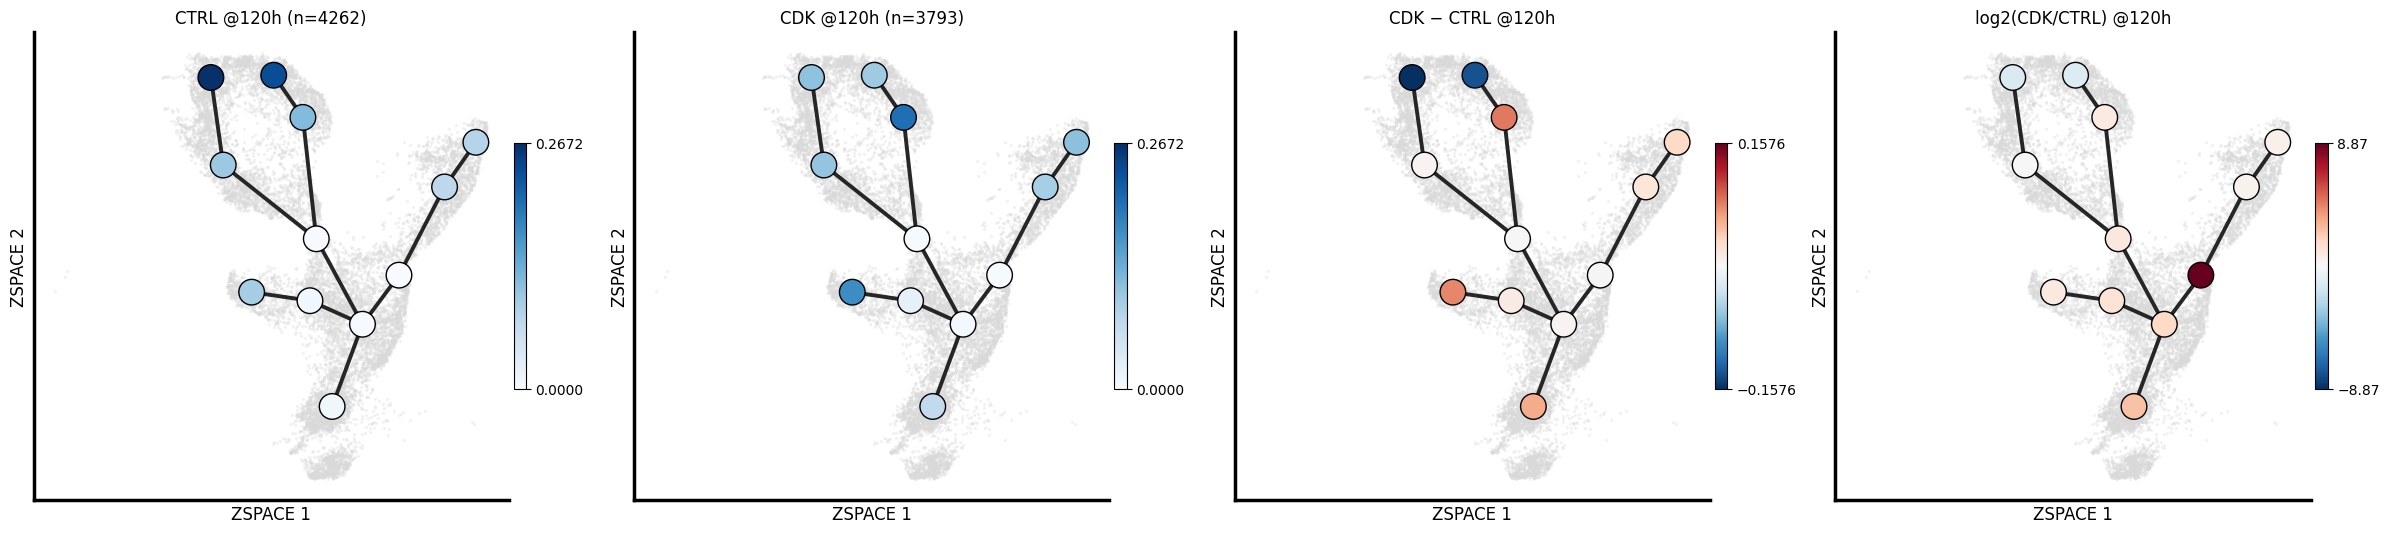

In [11]:
K = len(valid_idx)

T_TARGET = 120.0
def proportions_at_time(df_in, t_value):
    sel = df_in[np.isclose(df_in[TIME_COL].astype(float).values, float(t_value))]
    if sel.shape[0] == 0:
        return np.zeros(K), 0

    cell_xy = sel[[X_COL, Y_COL]].to_numpy(float)

    D2 = ((cell_xy[:, None, :] - node_xy_valid[None, :, :])**2).sum(axis=2)
    closest = D2.argmin(axis=1)
    cnt = np.bincount(closest, minlength=K)
    total = int(cnt.sum())

    return (cnt / max(total, 1)), total


p_ctrl, n_ctrl = proportions_at_time(control_df, T_TARGET)
p_cdk,  n_cdk  = proportions_at_time(cdk_df,     T_TARGET)

diff = p_cdk - p_ctrl
eps = 1e-6
scaled = np.log2((p_cdk + eps) / (p_ctrl + eps))


# ---------------- plotting ----------------

def draw_tree_background(ax):
    # background UMAP
    ax.scatter(control_df[X_COL], control_df[Y_COL],
               s=5, c=(0.85,0.85,0.85),
               alpha=0.35, linewidths=0, zorder=0)

    # edges
    dark = (0.15, 0.15, 0.15)
    for u, v in connections_valid:
        ax.plot([node_xy_valid[u, 0], node_xy_valid[v, 0]],
                [node_xy_valid[u, 1], node_xy_valid[v, 1]],
                lw=2.8, c=dark, zorder=2)

    ax.set_aspect("equal")
    ax.set_xlabel("ZSPACE 1", fontsize=12)
    ax.set_ylabel("ZSPACE 2", fontsize=12)

    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    for s in ["left", "bottom"]:
        ax.spines[s].set_linewidth(2.5)
        ax.spines[s].set_color("black")

    ax.set_xticks([])
    ax.set_yticks([])


fig, axes = plt.subplots(1, 4, figsize=(24, 7), sharex=True, sharey=True)

# 1) CTRL proportions
vmin_ab = float(min(np.min(p_ctrl), np.min(p_cdk)))
vmax_ab = float(max(np.max(p_ctrl), np.max(p_cdk)))
if not np.isfinite(vmin_ab) or not np.isfinite(vmax_ab) or np.isclose(vmin_ab, vmax_ab):
    vmin_ab, vmax_ab = 0.0, 1.0

norm_ab = mpl.colors.Normalize(vmin=vmin_ab, vmax=vmax_ab)
cmap_ab = mpl.cm.get_cmap("Blues")

ax = axes[0]; draw_tree_background(ax)
ax.scatter(node_xy_valid[:, 0], node_xy_valid[:, 1],
           c=p_ctrl, cmap=cmap_ab, norm=norm_ab,
           s=340, edgecolor="k", linewidth=1.0, zorder=3)
ax.set_title(f"CTRL @120h (n={n_ctrl})")

fig.colorbar(mpl.cm.ScalarMappable(cmap=cmap_ab, norm=norm_ab),
             ax=ax, location="right", fraction=0.025, pad=0.01,
             ticks=[vmin_ab, vmax_ab])


# 2) CDK proportions
ax = axes[1]; draw_tree_background(ax)
ax.scatter(node_xy_valid[:, 0], node_xy_valid[:, 1],
           c=p_cdk, cmap=cmap_ab, norm=norm_ab,
           s=340, edgecolor="k", linewidth=1.0, zorder=3)
ax.set_title(f"CDK @120h (n={n_cdk})")

fig.colorbar(mpl.cm.ScalarMappable(cmap=cmap_ab, norm=norm_ab),
             ax=ax, location="right", fraction=0.025, pad=0.01,
             ticks=[vmin_ab, vmax_ab])


# 3) Difference (CDK − CTRL)
amax = float(np.nanmax(np.abs(diff))) if diff.size else 1.0
if not np.isfinite(amax) or amax == 0:
    amax = 1.0

norm_d = mpl.colors.Normalize(vmin=-amax, vmax=amax)
cmap_d = mpl.cm.get_cmap("RdBu_r")

ax = axes[2]; draw_tree_background(ax)
ax.scatter(node_xy_valid[:, 0], node_xy_valid[:, 1],
           c=diff, cmap=cmap_d, norm=norm_d,
           s=340, edgecolor="k", linewidth=1.0, zorder=3)
ax.set_title("CDK − CTRL @120h")

fig.colorbar(mpl.cm.ScalarMappable(cmap=cmap_d, norm=norm_d),
             ax=ax, location="right", fraction=0.025, pad=0.01,
             ticks=[-amax, amax])


# 4) Scaled / log2
amax_s = float(np.nanpercentile(np.abs(scaled), 98)) if scaled.size else 1.0
if not np.isfinite(amax_s) or amax_s == 0:
    amax_s = 1.0

norm_s = mpl.colors.Normalize(vmin=-amax_s, vmax=amax_s)

ax = axes[3]; draw_tree_background(ax)
ax.scatter(node_xy_valid[:, 0], node_xy_valid[:, 1],
           c=scaled, cmap=cmap_d, norm=norm_s,
           s=340, edgecolor="k", linewidth=1.0, zorder=3)
ax.set_title("log2(CDK/CTRL) @120h")

fig.colorbar(mpl.cm.ScalarMappable(cmap=cmap_d, norm=norm_s),
             ax=ax, location="right", fraction=0.025, pad=0.01,
             ticks=[-amax_s, amax_s])


fig.tight_layout()
plt.show()


/tmp/ipykernel_1796526/2305455064.py:38: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(control_df[X_COL], control_df[Y_COL],


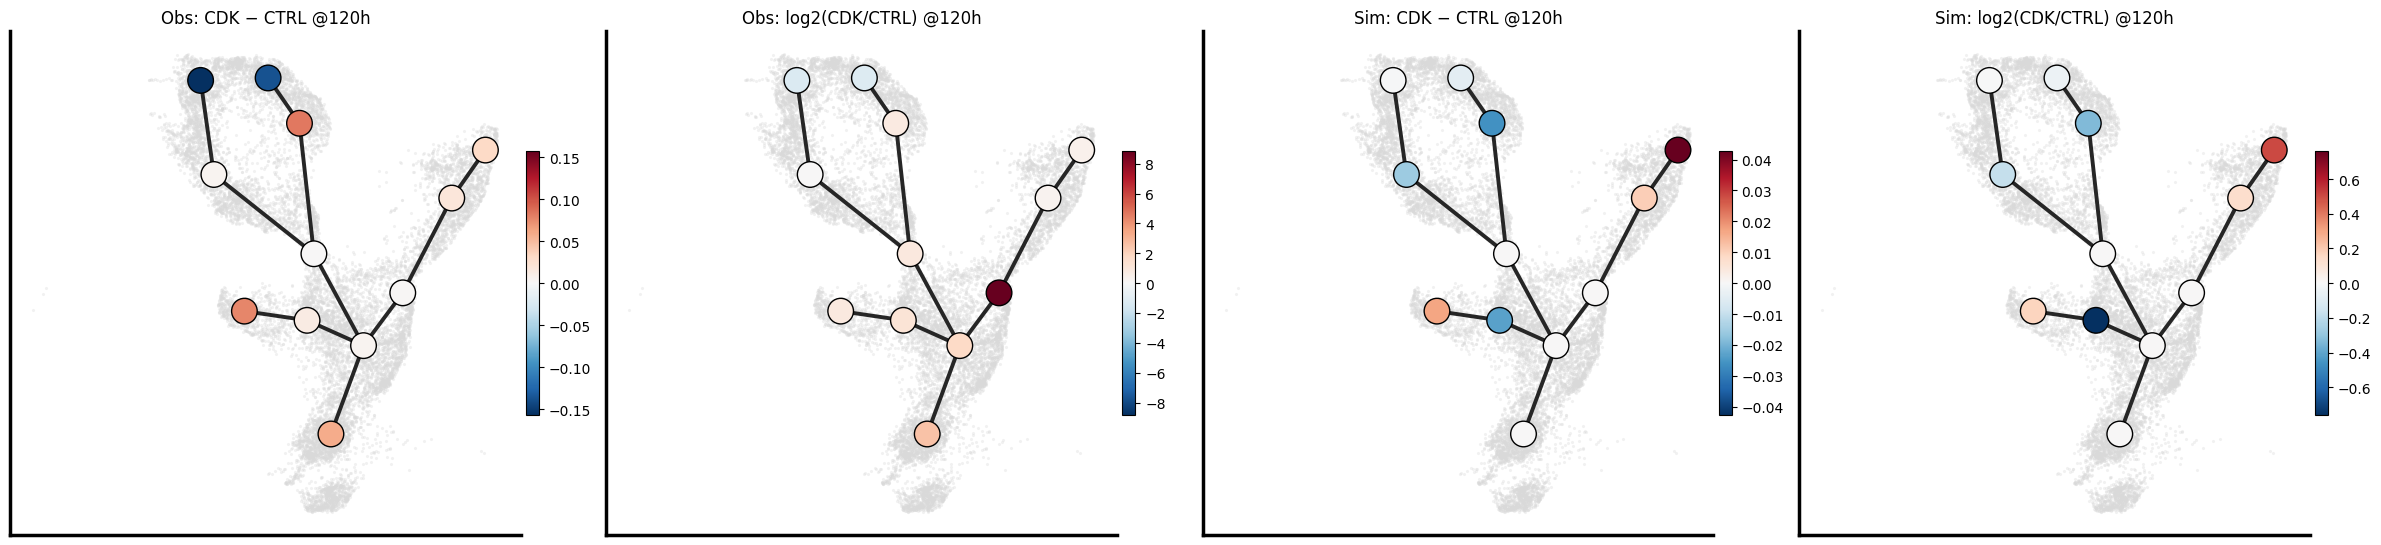

In [12]:



# ---------------- time index ----------------
times = np.asarray(times, dtype=float)
if np.any(np.isclose(times, T_TARGET)):
    ti = int(np.where(np.isclose(times, T_TARGET))[0][0])
else:
    ti = len(times) - 1
t_label = float(times[ti])

# ---------------- simulated values ----------------
p_ctrl_sim = P_sim[ti]
p_cdk_sim  = P_sim_cdk[ti]

# ---------------- observed contrasts ----------------
diff_obs = p_cdk - p_ctrl
log2_obs = np.log2((p_cdk + eps) / (p_ctrl + eps))

# ---------------- simulated contrasts ----------------
diff_sim = p_cdk_sim - p_ctrl_sim
log2_sim = np.log2((p_cdk_sim + eps) / (p_ctrl_sim + eps))

# ---------------- valid nodes only ----------------
finite = np.isfinite(CC_periods)
valid_idx = np.nonzero(finite)[0]
node_xy_valid = node_xy[valid_idx]

orig_to_valid = {orig: new for new, orig in enumerate(valid_idx)}
connections_valid = [
    (orig_to_valid[u], orig_to_valid[v])
    for (u, v) in connections
    if u in orig_to_valid and v in orig_to_valid
]

# ---------------- plotting ----------------
fig, axes = plt.subplots(1, 4, figsize=(24, 7), sharex=True, sharey=True)

# background (same for all)
for ax in axes:
    ax.scatter(control_df[X_COL], control_df[Y_COL],
               s=5, c=(0.85, 0.85, 0.85),
               alpha=0.35, linewidths=0, zorder=0)

    for u, v in connections_valid:
        ax.plot([node_xy_valid[u, 0], node_xy_valid[v, 0]],
                [node_xy_valid[u, 1], node_xy_valid[v, 1]],
                lw=2.8, c=(0.15, 0.15, 0.15), zorder=2)

    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])

    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    for s in ["left", "bottom"]:
        ax.spines[s].set_linewidth(2.5)
        ax.spines[s].set_color("black")

# ---------------- panel 1: observed diff ----------------
amax = np.nanmax(np.abs(diff_obs)) or 1.0
norm = mpl.colors.Normalize(vmin=-amax, vmax=amax)

axes[0].scatter(node_xy_valid[:, 0], node_xy_valid[:, 1],
                c=diff_obs, cmap="RdBu_r", norm=norm,
                s=340, edgecolor="k", linewidth=1.0, zorder=3)
axes[0].set_title(f"Obs: CDK − CTRL @{t_label:.0f}h")

plt.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap="RdBu_r"),
             ax=axes[0], fraction=0.025, pad=0.01)

# ---------------- panel 2: observed log2 ----------------
amax = np.nanpercentile(np.abs(log2_obs), 98) or 1.0
norm = mpl.colors.Normalize(vmin=-amax, vmax=amax)

axes[1].scatter(node_xy_valid[:, 0], node_xy_valid[:, 1],
                c=log2_obs, cmap="RdBu_r", norm=norm,
                s=340, edgecolor="k", linewidth=1.0, zorder=3)
axes[1].set_title(f"Obs: log2(CDK/CTRL) @{t_label:.0f}h")

plt.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap="RdBu_r"),
             ax=axes[1], fraction=0.025, pad=0.01)

# ---------------- panel 3: simulated diff ----------------
amax = np.nanmax(np.abs(diff_sim)) or 1.0
norm = mpl.colors.Normalize(vmin=-amax, vmax=amax)

axes[2].scatter(node_xy_valid[:, 0], node_xy_valid[:, 1],
                c=diff_sim, cmap="RdBu_r", norm=norm,
                s=340, edgecolor="k", linewidth=1.0, zorder=3)
axes[2].set_title(f"Sim: CDK − CTRL @{t_label:.0f}h")

plt.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap="RdBu_r"),
             ax=axes[2], fraction=0.025, pad=0.01)

# ---------------- panel 4: simulated log2 ----------------
amax = np.nanpercentile(np.abs(log2_sim), 98) or 1.0
norm = mpl.colors.Normalize(vmin=-amax, vmax=amax)

axes[3].scatter(node_xy_valid[:, 0], node_xy_valid[:, 1],
                c=log2_sim, cmap="RdBu_r", norm=norm,
                s=340, edgecolor="k", linewidth=1.0, zorder=3)
axes[3].set_title(f"Sim: log2(CDK/CTRL) @{t_label:.0f}h")

plt.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap="RdBu_r"),
             ax=axes[3], fraction=0.025, pad=0.01)

plt.tight_layout()
plt.show()


/tmp/ipykernel_1796526/2981137545.py:40: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap("RdBu_r")
/tmp/ipykernel_1796526/2981137545.py:46: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(


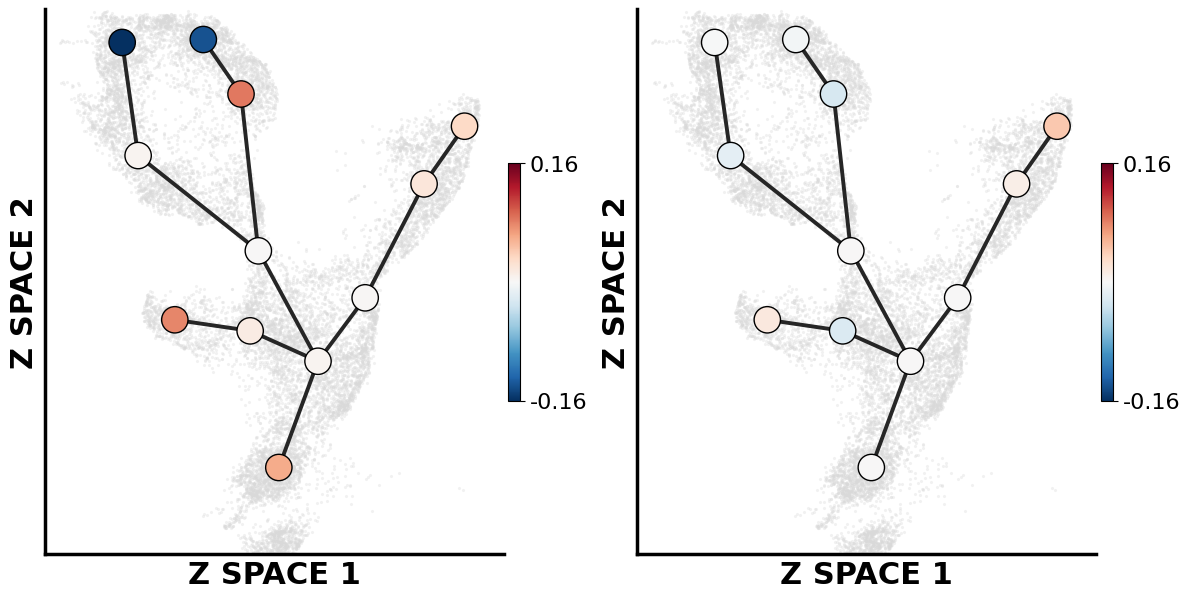

In [13]:
# ---------------- time index ----------------
times = np.asarray(times, dtype=float)
if np.any(np.isclose(times, T_TARGET)):
    ti = int(np.where(np.isclose(times, T_TARGET))[0][0])
else:
    ti = len(times) - 1
t_label = float(times[ti])

# ---------------- simulated values ----------------
p_ctrl_sim = P_sim[ti]
p_cdk_sim  = P_sim_cdk[ti]

# ---------------- observed & simulated contrasts ----------------
diff_obs = p_cdk - p_ctrl
diff_sim = p_cdk_sim - p_ctrl_sim

# ---------------- valid nodes only ----------------
finite = np.isfinite(CC_periods)
valid_idx = np.nonzero(finite)[0]
node_xy_valid = node_xy[valid_idx]

orig_to_valid = {orig: new for new, orig in enumerate(valid_idx)}
connections_valid = [
    (orig_to_valid[u], orig_to_valid[v])
    for (u, v) in connections
    if u in orig_to_valid and v in orig_to_valid
]

# ---------------- shared colormap scale ----------------
vals = np.concatenate([
    diff_obs[np.isfinite(diff_obs)],
    diff_sim[np.isfinite(diff_sim)]
])
amax = np.nanmax(np.abs(vals)) if vals.size else 1.0
if not np.isfinite(amax) or amax == 0:
    amax = 1.0

vmin, vmax = -amax, amax
norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax)
cmap = mpl.cm.get_cmap("RdBu_r")

# ---------------- plotting ----------------
fig, axes = plt.subplots(1, 2, figsize=(12, 7), sharex=True, sharey=True)

for ax in axes:
    ax.scatter(
        control_df[X_COL], control_df[Y_COL],
        s=5, c=(0.85, 0.85, 0.85),
        alpha=0.35, linewidths=0, zorder=0
    )

    for u, v in connections_valid:
        ax.plot(
            [node_xy_valid[u, 0], node_xy_valid[v, 0]],
            [node_xy_valid[u, 1], node_xy_valid[v, 1]],
            lw=2.8, c=(0.15, 0.15, 0.15), zorder=2
        )

    ax.set_aspect("equal")
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_xticks([])
    ax.set_yticks([])

    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    for s in ["left", "bottom"]:
        ax.spines[s].set_linewidth(2.5)
        ax.spines[s].set_color("black")

# ---------------- axis labels (bold & big) ----------------
axes[0].set_xlabel("Z SPACE 1", fontsize=22, fontweight="bold")
axes[0].set_ylabel("Z SPACE 2", fontsize=22, fontweight="bold")
axes[1].set_xlabel("Z SPACE 1", fontsize=22, fontweight="bold")
axes[1].set_ylabel("Z SPACE 2", fontsize=22, fontweight="bold")

# -------- panel 1: observed diff --------
axes[0].scatter(
    node_xy_valid[:, 0], node_xy_valid[:, 1],
    c=diff_obs, cmap=cmap, norm=norm,
    s=360, edgecolor="k", linewidth=1.0, zorder=3
)

cbar1 = plt.colorbar(
    mpl.cm.ScalarMappable(norm=norm, cmap=cmap),
    ax=axes[0], fraction=0.025, pad=0.01,
    ticks=[vmin, vmax]
)
cbar1.ax.yaxis.set_major_formatter(mpl.ticker.FormatStrFormatter('%.2f'))
cbar1.ax.tick_params(labelsize=16)

# -------- panel 2: simulated diff --------
axes[1].scatter(
    node_xy_valid[:, 0], node_xy_valid[:, 1],
    c=diff_sim, cmap=cmap, norm=norm,
    s=360, edgecolor="k", linewidth=1.0, zorder=3
)

cbar2 = plt.colorbar(
    mpl.cm.ScalarMappable(norm=norm, cmap=cmap),
    ax=axes[1], fraction=0.025, pad=0.01,
    ticks=[vmin, vmax]
)
cbar2.ax.yaxis.set_major_formatter(mpl.ticker.FormatStrFormatter('%.2f'))
cbar2.ax.tick_params(labelsize=16)

plt.tight_layout()

fig.savefig(
    "FIGURES/Proportions_diff.png",
    dpi=500,
    bbox_inches="tight",
    transparent=True
)

plt.show()


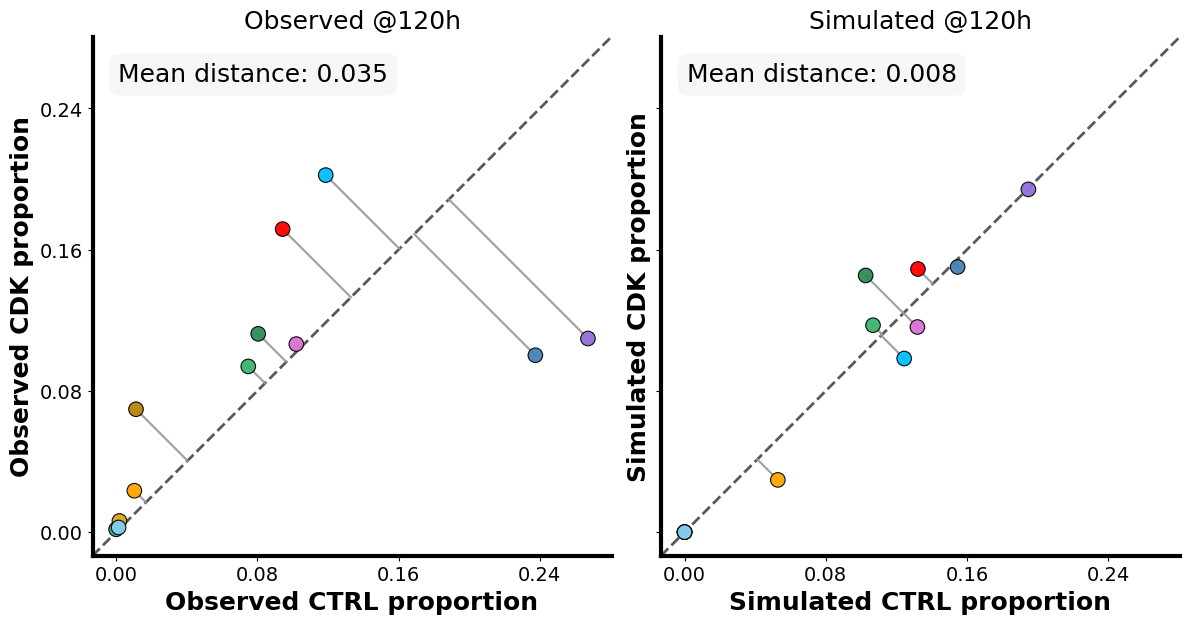

In [ ]:


# ---------------- settings ----------------
s = 110        # dot size
alpha = 0.95   # dot transparency

palette = [
    'darkgoldenrod', 'goldenrod', 'orange', 'red','lightseagreen','mediumseagreen', 'seagreen',
     'skyblue', 'orchid', 'mediumpurple',
    'deepskyblue', 'steelblue'
]

# ---------------- time index ----------------
times = np.asarray(times, dtype=float)
if np.any(np.isclose(times, T_TARGET)):
    ti = int(np.where(np.isclose(times, T_TARGET))[0][0])
else:
    ti = len(times) - 1
t_label = float(times[ti])

# ---------------- data ----------------
x_obs = np.asarray(p_ctrl, dtype=float)
y_obs = np.asarray(p_cdk,  dtype=float)
x_sim = np.asarray(P_sim[ti],     dtype=float)
y_sim = np.asarray(P_sim_cdk[ti], dtype=float)

finite = np.isfinite(CC_periods)
x_obs, y_obs = x_obs[finite], y_obs[finite]
x_sim, y_sim = x_sim[finite], y_sim[finite]

colors = [palette[i % len(palette)] for i in range(len(x_obs))]

# ---------------- shared limits ----------------
vals = np.concatenate([x_obs, y_obs, x_sim, y_sim])
vmin, vmax = np.nanmin(vals), np.nanmax(vals)
pad = 0.05 * (vmax - vmin if vmax > vmin else 1.0)
xlim = ylim = (vmin - pad, vmax + pad)


def draw_panel(ax, x, y, xlabel, ylabel, s, alpha):
    # diagonal
    ax.plot(xlim, ylim, '--', lw=2.0, c='0.35', zorder=1)

    # perpendicular distances
    proj = 0.5 * (x + y)
    for xi, yi, pi in zip(x, y, proj):
        ax.plot([xi, pi], [yi, pi], c='0.6', lw=1.6, alpha=0.9, zorder=2)

    # scatter
    ax.scatter(x, y, s=s, c=colors, edgecolor='k',
               linewidth=0.8, alpha=alpha, zorder=3)

    # mean distance
    dists = np.abs(y - x) / np.sqrt(2)
    ax.text(
        0.05, 0.95, f"Mean distance: {np.mean(dists):.3f}",
        transform=ax.transAxes, ha='left', va='top', fontsize=18,
        bbox=dict(boxstyle='round,pad=0.35',
                  facecolor=(0.96,0.96,0.96,0.9), edgecolor='none')
    )

    # styling
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlim(xlim); ax.set_ylim(ylim)
    ax.set_xlabel(xlabel, fontsize=18, fontweight='bold')
    ax.set_ylabel(ylabel, fontsize=18, fontweight='bold')
    ax.xaxis.set_major_locator(MaxNLocator(4))
    ax.yaxis.set_major_locator(MaxNLocator(4))
    ax.tick_params(labelsize=14)

    for spine in ['top','right']:
        ax.spines[spine].set_visible(False)
    for spine in ['left','bottom']:
        ax.spines[spine].set_linewidth(3)
        ax.spines[spine].set_color('black')

# ---------------- plotting ----------------
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharex=True, sharey=True)

draw_panel(
    axes[0], x_obs, y_obs,
    xlabel="Observed CTRL proportion",
    ylabel="Observed CDK proportion",
    s=s, alpha=alpha
)
axes[0].set_title(f"Observed @{t_label:.0f}h", fontsize=18)

draw_panel(
    axes[1], x_sim, y_sim,
    xlabel="Simulated CTRL proportion",
    ylabel="Simulated CDK proportion",
    s=s, alpha=alpha
)
axes[1].set_title(f"Simulated @{t_label:.0f}h", fontsize=18)

fig.tight_layout()

fig.savefig(
    "FIGURES/Proportions_diff_scatter.png",
    dpi=500,
    bbox_inches="tight",
    transparent=True
)


plt.show()